# **Recomendación de música con datos de Last.fm**


El objetivo es construir un sistema de recomendación de Música utilizando los datos de [Last.fm](https://www.last.fm/) provistos  abiertamente por [grouplens](https://grouplens.org/about/what-is-grouplens/) para: **"avanzar la teoría y la práctica de la computación social mediante la construcción y la comprensión de sistemas *(de recomendación)* utilizados por personas reales".**

Los datos contienen información sobre artistas, usuarios, y las veces que estos escucharon sus canciones. También está disponible un archivo README que contiene más información sobre las bases.


## **1. Carga de datos**

Se usan dos archivos de la base de [GroupLens](https://grouplens.org/datasets/hetrec-2011/):

- `artists.dat`: identificador (`id`) y nombre (`name`) de cada artista.
- `user_artists.dat`: usuario (`userID`), artista (`artistID`) y número de reproducciones (`weight`).

Se seleccionan y renombran las columnas necesarias y se unen ambas bases por el identificador del artista.


In [5]:

import pandas as pd
import numpy as np

# 1. Base de artistas: nos quedamos con id y name, y renombramos
artists = pd.read_csv('artists.dat', sep='\t')
artists = artists[['id', 'name']]
artists = artists.rename(columns={'id': 'artistID', 'name': 'artista'})

# 2. Base de usuario-artista: renombramos weight -> nro_reproducciones
user_artists = pd.read_csv('user_artists.dat', sep='\t')
user_artists = user_artists.rename(columns={'weight': 'nro_reproducciones'})

artists.head()

,artistID,artista
0,1,MALICE MIZER
1,2,Diary of Dreams
2,3,Carpathian Forest
3,4,Moi dix Mois
4,5,Bella Morte


In [6]:
user_artists.head()

,userID,artistID,nro_reproducciones
0,2,51,13883
1,2,52,11690
2,2,53,11351
3,2,54,10300
4,2,55,8983


Se hicieron distintas cosas para tener la distribución adecuada de las bases de datos:

1.  Se extrajo el ID y el nombre de la base de datos de los artistas y se ajustaron los nombres de las columnas.
2.  De la base de datos de las reproducciones se camabió únicamente el nombre de ***"weight"*** por ***"nor_reproducciones"***

Esto permite que las bases de datos sean comparables y manipulables conjuntamente.


## **2. Análisis descriptivo de los datos**

### 2.1 Top 10 de artistas por reproducciones (absolutas y porcentuales)


In [7]:

# Unimos las dos bases usando artistID como llave
datos = user_artists.merge(artists, on='artistID', how='left')

# --- Top 10 en número absoluto de reproducciones ---
top_abs = datos.groupby('artista')['nro_reproducciones'].sum().sort_values(ascending=False).head(10)
top_abs_df = top_abs.reset_index().rename(columns={'nro_reproducciones': 'reproducciones_totales'})
top_abs_df

,artista,reproducciones_totales
0,Britney Spears,2393140
1,Depeche Mode,1301308
2,Lady Gaga,1291387
3,Christina Aguilera,1058405
4,Paramore,963449
5,Madonna,921198
6,Rihanna,905423
7,Shakira,688529
8,The Beatles,662116
9,Katy Perry,532545


In [15]:
# --- Top 10 en porcentaje sobre el total de reproducciones ---
total_reproducciones = datos['nro_reproducciones'].sum()

top_pct = (datos.groupby('artista')['nro_reproducciones'].sum() / total_reproducciones * 100).sort_values(ascending=False).head(10)
top_pct_df = top_pct.reset_index().rename(columns={'nro_reproducciones': 'porcentaje_reproducciones'})
top_pct_df

,artista,porcentaje_reproducciones
0,Britney Spears,3.459096
1,Depeche Mode,1.880938
2,Lady Gaga,1.866598
3,Christina Aguilera,1.529841
4,Paramore,1.392590
5,Madonna,1.331519
6,Rihanna,1.308718
7,Shakira,0.995215
8,The Beatles,0.957037
9,Katy Perry,0.769752


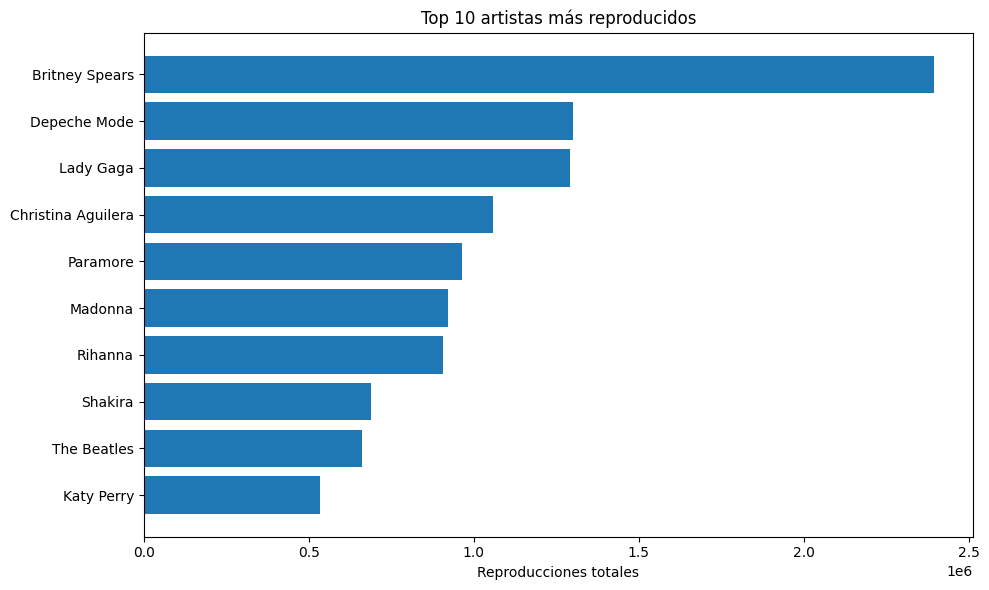

In [16]:
# --- Gráfica del top 10 en número absoluto ---
import matplotlib.pyplot as plt

plt.figure(figsize=(10,6))
plt.barh(top_abs_df['artista'][::-1], top_abs_df['reproducciones_totales'][::-1])
plt.xlabel('Reproducciones totales')
plt.title('Top 10 artistas más reproducidos')
plt.tight_layout()
plt.show()

En la sección **2.1** el procedimiento fue el procesamiento de los datos para identificar los artistas con mayores reproducciones según los datos.

Primero se presenta la ***cantidad bruta*** de esta representación. Después, se presentan a manera de proporción porcentual, lograda con un procedimiento simple al dividir las reproducciones por el artista sobre el total de reproducciones y después multiplicando por 100.


Es indispensable ser conscientes que la distribución de reproducciones por artista parece estar respondiendo a un desbalance considerable.


El artista más reproducido en la base es Britney Spears, con 2.393.140 reproducciones, equivalentes al 3.46% del total de reproducciones registradas en la plataforma — una distancia notable frente al segundo lugar (Depeche Mode, 1.3 millones, 1.88%).

El resto del top 10 está dominado por artistas pop/mainstream de los 2000 (Lady Gaga, Christina Aguilera, Madonna, Rihanna, Shakira, Katy Perry), con la única excepción de The Beatles.

Es interesante notar que incluso el artista más escuchado no alcanza el 4% del total de reproducciones, lo que sugiere una cola larga (long tail).

### 2.2 Top 10 de artistas por alcance (porcentaje de usuarios que los escucharon al menos una vez)


In [17]:
# Número total de usuarios únicos en la base
total_usuarios = datos['userID'].nunique()

# Para cada artista, contamos usuarios distintos que lo escucharon
alcance = datos.groupby('artista')['userID'].nunique()

# Convertimos a porcentaje y tomamos el top 10
alcance_pct = (alcance / total_usuarios * 100).sort_values(ascending=False).head(10)
alcance_pct_df = alcance_pct.reset_index().rename(columns={'userID': 'porcentaje_usuarios'})
alcance_pct_df

,artista,porcentaje_usuarios
0,Lady Gaga,32.293869
1,Britney Spears,27.589852
2,Rihanna,25.581395
3,The Beatles,25.369979
4,Katy Perry,25.000000
5,Madonna,22.674419
6,Avril Lavigne,22.040169
7,Christina Aguilera,21.511628
8,Muse,21.141649
9,Paramore,21.088795


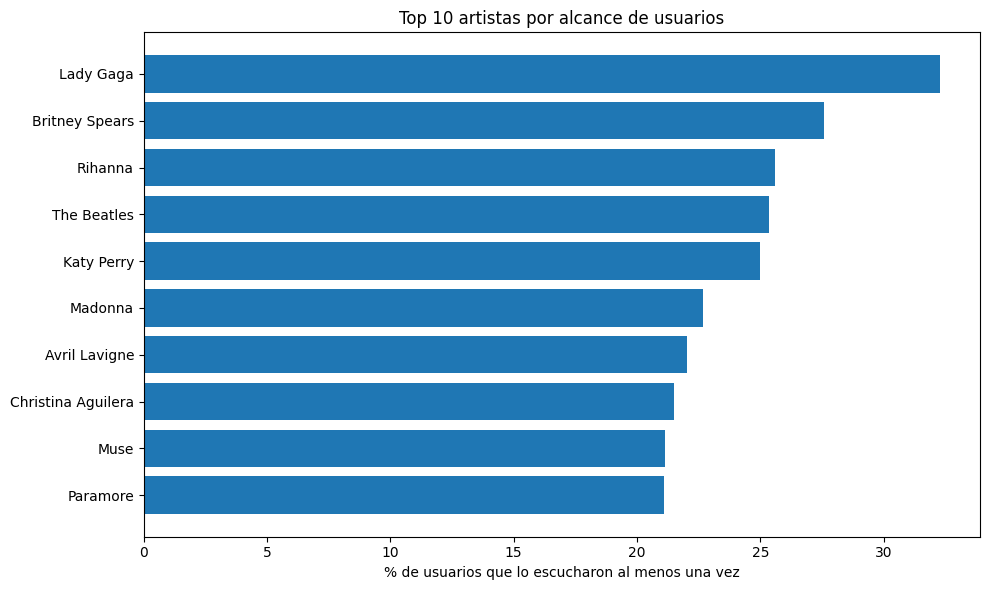

In [18]:
# --- Gráfica del top 10 por alcance ---
import matplotlib.pyplot as plt

plt.figure(figsize=(10,6))
plt.barh(alcance_pct_df['artista'][::-1], alcance_pct_df['porcentaje_usuarios'][::-1])
plt.xlabel('% de usuarios que lo escucharon al menos una vez')
plt.title('Top 10 artistas por alcance de usuarios')
plt.tight_layout()
plt.show()

En la sección **2.2** el procedimiento consistió en calcular, para cada artista, el número de usuarios distintos que lo escucharon al menos una vez, y dividirlo sobre el total de usuarios únicos de la plataforma, expresando el resultado como porcentaje.

A diferencia de la sección **2.1**, aquí no importa cuántas veces un usuario repitió al artista, sino simplemente si lo escuchó o no. Esta medida corresponde al concepto de *soporte* visto en el análisis de canasta de compra, aplicado a artistas en lugar de productos.

El resultado evidencia un cambio relevante en el ranking: Lady Gaga pasa a ser el artista con mayor alcance (32.3% de los usuarios la escucharon al menos una vez), desplazando a Britney Spears al segundo lugar (27.5%), pese a que esta última concentraba casi el doble de reproducciones totales en el punto anterior. Esto sugiere que Britney Spears tiene un grupo más reducido de oyentes, pero que la reproducen con mucha mayor intensidad (fans más "fieles" o con escucha repetitiva), mientras que Lady Gaga es escuchada por una base de usuarios más amplia, aunque en promedio con menor frecuencia por usuario.

También aparecen en este top 10 artistas que no figuraban en el ranking por volumen, como Avril Lavigne y Muse, lo que confirma que ambas métricas —volumen y alcance— capturan dimensiones distintas de la popularidad de un artista y no deben usarse de forma intercambiable.

### 2.3 Perfil del usuario 8: sus 10 artistas más escuchados


In [19]:
usuario8 = datos[datos['userID'] == 8].sort_values('nro_reproducciones', ascending=False).head(10)
usuario8_tabla = usuario8[['artista', 'nro_reproducciones']].reset_index(drop=True)
usuario8_tabla

,artista,nro_reproducciones
0,No Angels,6291
1,Sandy,2396
2,Britney Spears,2258
3,Vanessa Petruo,1735
4,Beyoncé,1425
5,Alexander,1407
6,Sugababes,1039
7,Queensberry,963
8,Lady Gaga,921
9,Fady Maalouf,819


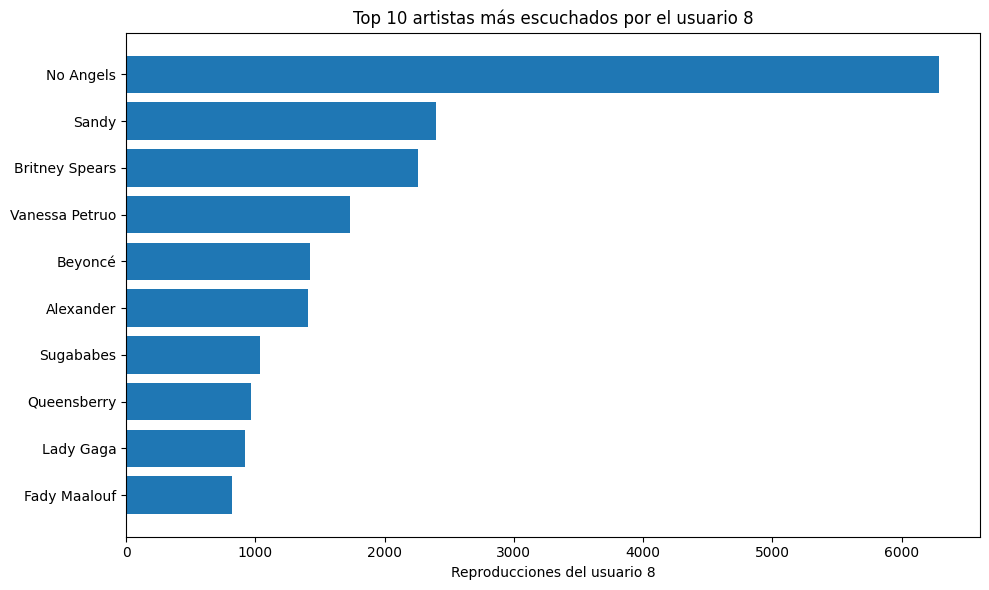

In [20]:

# --- Gráfica del top 10 del usuario 8 ---
import matplotlib.pyplot as plt

plt.figure(figsize=(10,6))
plt.barh(usuario8_tabla['artista'][::-1], usuario8_tabla['nro_reproducciones'][::-1])
plt.xlabel('Reproducciones del usuario 8')
plt.title('Top 10 artistas más escuchados por el usuario 8')
plt.tight_layout()
plt.show()

**Resultados.** El usuario 8 concentra sus reproducciones de forma muy marcada en un solo artista: No Angels, con 6.291 reproducciones, casi el triple que el segundo lugar (Sandy, 2.396). A partir de ahí la caída es mucho más suave, con valores entre 2.396 y 819 reproducciones para el resto del top 10.

**Patrón.** Al observar los diez artistas se identifican dos grupos superpuestos:

- **Pop mainstream internacional**: Britney Spears, Beyoncé, Lady Gaga — artistas que también aparecían en los rankings generales de las secciones 2.1 y 2.2, consistentes con el gusto "promedio" de la plataforma.
- **Pop/escena alemana**: No Angels (la más escuchada, por amplio margen), Sandy, Vanessa Petruo, Alexander y Fady Maalouf. Estos cinco artistas comparten un origen común: No Angels es un girl group alemán, y Sandy, Vanessa Petruo, Alexander (Klaws) y Fady Maalouf están vinculados al casting show *Deutschland sucht den Superstar* (DSDS), el "Idol" alemán.

**Interpretación.** El patrón dominante no es un género musical en el sentido estricto (pop, en todos los casos), sino un **origen geográfico/cultural**: el usuario parece tener una afinidad particular por la escena pop de habla alemana, posiblemente ligada a un programa de televisión específico (DSDS), complementada con el consumo de pop internacional que también domina el resto de la base. Esta es una hipótesis razonable a partir de los nombres de los artistas, no un hecho verificado con metadatos adicionales (por ejemplo, país de origen declarado en `artists.dat`, que no estamos usando En este proyecto).

Este patrón resulta relevante de cara a la Sección 3: un recomendador que ignore esta preferencia "de nicho" (por ejemplo, uno que solo promedie reproducciones globales) corre el riesgo de recomendarle al usuario 8 artistas pop genéricos, pasando por alto el componente alemán que parece ser el núcleo de su gusto musical.

## **3. Generando recomendaciones**

Se construyen cuatro recomendadores para el usuario 8 y se comparan sus recomendaciones.


### 3.1. Filtrado colaborativo sencillo: promedios

Top 10 de recomendaciones a partir del promedio de reproducciones de cada artista, con el tratamiento explícito de los artistas sin reproducciones.


In [21]:

# Construimos la matriz usuario-artista (equivalente a r_matrix)
r_matrix = datos.pivot_table(values='nro_reproducciones', index='userID', columns='artista')

# Promedio de reproducciones por artista, considerando solo a quienes lo escucharon
# (.mean() ignora los NaN automáticamente, sin necesidad de imputar)
promedio_artistas = r_matrix.mean(axis=0)

# Artistas que el usuario 8 ya escuchó, para excluirlos de la recomendación
artistas_escuchados_u8 = r_matrix.loc[8].dropna().index

# Top 10: excluimos lo ya escuchado y ordenamos de mayor a menor promedio
recomendaciones_promedio = (
    promedio_artistas.drop(artistas_escuchados_u8)
    .sort_values(ascending=False)
    .head(10)
)
recomendaciones_promedio_df = recomendaciones_promedio.reset_index()
recomendaciones_promedio_df.columns = ['artista', 'promedio_reproducciones']
recomendaciones_promedio_df

,artista,promedio_reproducciones
0,Viking Quest,35323.000000
1,Tyler Adam,30614.000000
2,Rytmus,23462.000000
3,Johnny Hallyday,16497.500000
4,Dicky Dixon,15345.000000
5,RICHARD DIXON-COMPOSER,14082.000000
6,Thalía,13462.884615
7,80kidz,12520.000000
8,Tribraco,10776.000000
9,Kontrafakt,10726.000000


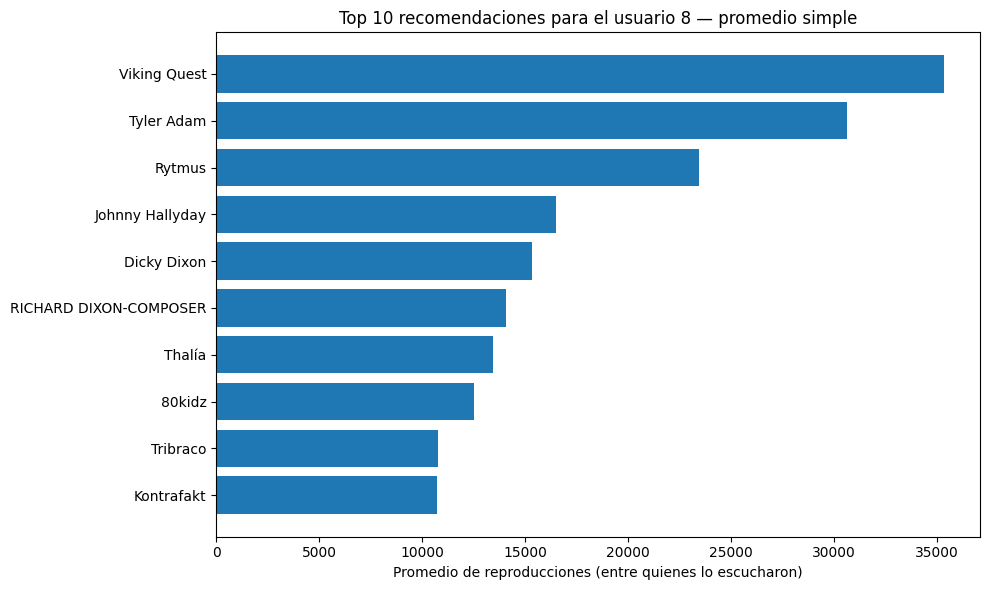

In [22]:
# --- Gráfica de las recomendaciones por promedio simple ---
import matplotlib.pyplot as plt

plt.figure(figsize=(10,6))
plt.barh(recomendaciones_promedio_df['artista'][::-1], recomendaciones_promedio_df['promedio_reproducciones'][::-1])
plt.xlabel('Promedio de reproducciones (entre quienes lo escucharon)')
plt.title('Top 10 recomendaciones para el usuario 8 — promedio simple')
plt.tight_layout()
plt.show()

**Metodología.** Para generar las recomendaciones del usuario 8 mediante promedios simples, se construyó primero la matriz usuario-artista (`r_matrix`), donde cada fila es un usuario, cada columna un artista, y cada celda el número de reproducciones; las combinaciones usuario-artista sin interacción quedan como `NaN`. Sobre esta matriz se calculó el promedio de reproducciones de cada artista con `.mean(axis=0)`, método que excluye automáticamente los valores faltantes del cálculo, de modo que el promedio de cada artista se obtiene únicamente a partir de los usuarios que efectivamente lo escucharon, sin necesidad de imputar los `NaN` con cero (lo cual penalizaría artificialmente a artistas poco escuchados). Finalmente, se excluyeron del ranking los artistas que el usuario 8 ya había escuchado —pues no tiene sentido recomendar lo que ya conoce— y se ordenaron los restantes de mayor a menor promedio, reteniendo el top 10.

**Resultados.** El recomendador basado en promedio simple sugiere en primer lugar a Viking Quest (35.323 reproducciones promedio), seguido de Tyler Adam (30.614) y Rytmus (23.462) — valores notablemente altos en comparación con los promedios de popularidad general observados en la Sección 2 (donde incluso Britney Spears, el artista más reproducido de toda la plataforma, promediaba un orden de magnitud menor sobre el total de usuarios).

**Problema metodológico.** Esta discrepancia revela la principal debilidad de este recomendador: al promediar sin ponderar por el número de usuarios que efectivamente escucharon a cada artista, un artista con **pocos oyentes pero muy intensivos** (por ejemplo, dos o tres usuarios que lo reprodujeron miles de veces cada uno) puede desplazar en el ranking a artistas genuinamente populares y escuchados de forma consistente por miles de usuarios. Este es el mismo problema de **falta de robustez ante la micronumerosidad** que discutimos en el notebook de recomendadores simples (S05-1) al construir la métrica de IMDB: un promedio calculado sobre muy pocas observaciones no es representativo y debe penalizarse o ponderarse de alguna forma — algo que la fórmula de IMDB resuelve mezclando el promedio del ítem con el promedio global, ponderado por el número de votos.

**Interpretación.** Las recomendaciones generadas (Viking Quest, Tyler Adam, Rytmus, Dicky Dixon, RICHARD DIXON-COMPOSER, entre otros) corresponden probablemente a artistas de nicho con un número muy reducido de oyentes en la base, cuyo promedio está dominado por uno o pocos usuarios con reproducciones extremas. Esto hace que el recomendador, en su forma actual, no esté capturando similitud de gustos entre usuarios, sino simplemente ruido estadístico derivado del bajo soporte muestral de ciertos artistas. Esta limitación es la que se buscará corregir en la Sección 3.2 incorporando la similitud de coseno entre usuarios, de forma que el promedio se pondere por cuán parecidos son los demás usuarios al usuario 8, en lugar de tratarlos a todos por igual.

### 3.2.  Filtrado colaborativo sencillo: promedios ponderados

Top 10 de recomendaciones con un promedio ponderado por la similitud de coseno entre usuarios, comparado con el recomendador anterior.


In [23]:
from sklearn.metrics.pairwise import cosine_similarity

# Imputamos 0 solo para calcular similitud entre usuarios (no afecta el promedio final)
r_matrix_dummy = r_matrix.fillna(0)
cosine_sim = cosine_similarity(r_matrix_dummy, r_matrix_dummy)
cosine_sim = pd.DataFrame(cosine_sim, index=r_matrix.index, columns=r_matrix.index)

def recomendador_wmean(user_id, n=10):
    sim_scores_u = cosine_sim[user_id]
    artistas_escuchados = r_matrix.loc[user_id].dropna().index
    candidatos = r_matrix.columns.difference(artistas_escuchados)

    wmean_ratings = {}
    for artista in candidatos:
        m_ratings = r_matrix[artista].dropna()
        sim_scores = sim_scores_u.loc[m_ratings.index]
        if sim_scores.sum() > 0:
            wmean_ratings[artista] = np.dot(sim_scores, m_ratings) / sim_scores.sum()

    return pd.Series(wmean_ratings).sort_values(ascending=False).head(n)

recomendaciones_wmean = recomendador_wmean(8)
recomendaciones_wmean_df = recomendaciones_wmean.reset_index()
recomendaciones_wmean_df.columns = ['artista', 'promedio_ponderado']
recomendaciones_wmean_df

,artista,promedio_ponderado
0,Johnny Hallyday,32990.000000
1,Tyler Adam,30614.000000
2,Rytmus,23462.000000
3,The Devil Wears Prada,17097.666227
4,Hadouken!,13330.754741
5,The Classic Crime,12754.274950
6,X-Ray Dog,12091.000000
7,Kontrafakt,10726.000000
8,Holdcut,10574.000000
9,RoBERT,9615.000000


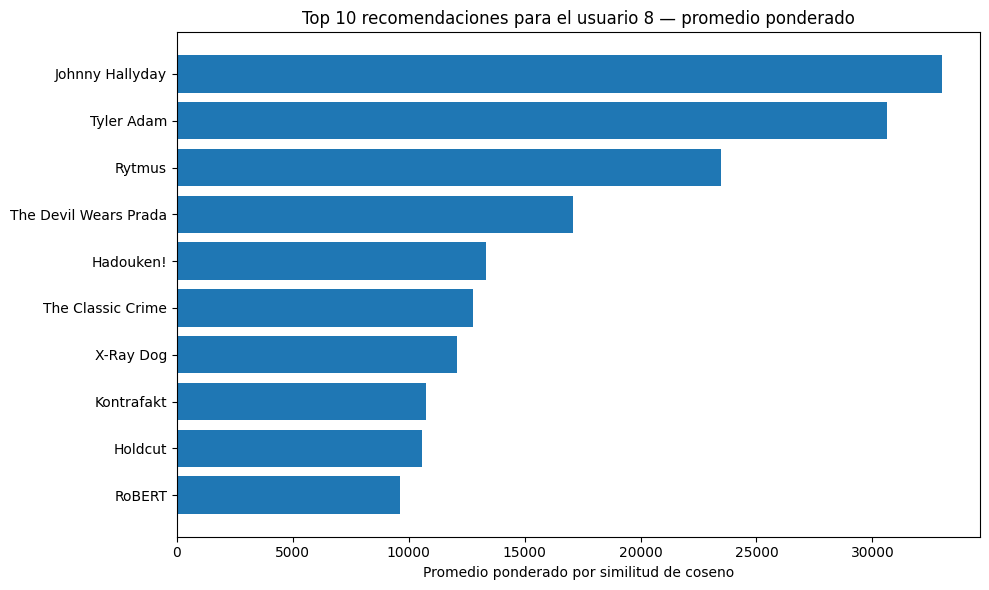

In [24]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10,6))
plt.barh(recomendaciones_wmean_df['artista'][::-1], recomendaciones_wmean_df['promedio_ponderado'][::-1])
plt.xlabel('Promedio ponderado por similitud de coseno')
plt.title('Top 10 recomendaciones para el usuario 8 — promedio ponderado')
plt.tight_layout()
plt.show()

**Metodología.** Se calculó la similitud de coseno entre todos los usuarios a partir de `r_matrix` imputada en 0, y para cada artista no escuchado por el usuario 8 se promedió el rating de quienes sí lo escucharon, ponderado por su similitud con el usuario 8. Se excluyeron los artistas ya escuchados y se retuvo el top 10.

**Resultados.** Johnny Hallyday encabeza ahora el ranking (32.990), seguido de Tyler Adam y Rytmus, que mantienen exactamente el mismo valor que en el promedio simple (30.614 y 23.462) — señal de que estos artistas tienen un único oyente en la base, por lo que ponderar no cambia nada.

**Comparación con 3.1.** La mitad del top 10 cambió: desaparecen Viking Quest, Dicky Dixon, RICHARD DIXON-COMPOSER, Thalía, 80kidz y Tribraco, y entran The Devil Wears Prada, Hadouken!, The Classic Crime, X-Ray Dog, Holdcut y RoBERT. Esto confirma que ponderar por similitud sí modifica el ranking frente al promedio ingenuo, aunque persisten en el top artistas de muy pocos oyentes (Tyler Adam, Rytmus), lo que indica que la ponderación por coseno no resuelve por sí sola el problema de micronumerosidad señalado en 3.1 — solo lo atenúa quitando peso a usuarios disímiles.

### 3.3.  Filtrado colaborativo usando SVD

Top 10 de recomendaciones por reconstrucción de bajo rango con SVD; el número de valores singulares se elige por RMSE en una partición entrenamiento/prueba.


In [26]:
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error
from scipy.sparse.linalg import svds

# Partimos en entrenamiento/prueba (sin estratificar: hay usuarios con una sola interacción)
train, test = train_test_split(datos, test_size=0.25, random_state=42)

R_train_df = train.pivot_table(index='userID', columns='artista', values='nro_reproducciones').fillna(0)
R_train = R_train_df.to_numpy()
user_means = R_train.mean(axis=1)
R_demeaned = R_train - user_means.reshape(-1, 1)

def rmse_k(k):
    U, sigma, Vt = svds(R_demeaned, k=k)
    pred = np.dot(np.dot(U, np.diag(sigma)), Vt) + user_means.reshape(-1, 1)
    pred_df = pd.DataFrame(pred, index=R_train_df.index, columns=R_train_df.columns)
    test_eval = test[test['artista'].isin(pred_df.columns) & test['userID'].isin(pred_df.index)]
    y_pred = [pred_df.loc[u, a] for u, a in zip(test_eval['userID'], test_eval['artista'])]
    return np.sqrt(mean_squared_error(test_eval['nro_reproducciones'], y_pred))

resultados_k = {k: rmse_k(k) for k in [5, 10, 20, 30, 50]}
resultados_k

{5: np.float64(3023.846704654952),
 10: np.float64(3022.385456539602),
 20: np.float64(3020.45706274416),
 30: np.float64(3019.1036856358714),
 50: np.float64(3029.2917774562447)}

In [27]:
# Elegimos el k con menor RMSE y reconstruimos con TODOS los datos (no solo train)
mejor_k = min(resultados_k, key=resultados_k.get)

R_full = r_matrix.fillna(0).to_numpy()
user_means_full = R_full.mean(axis=1)
R_full_demeaned = R_full - user_means_full.reshape(-1, 1)

U, sigma, Vt = svds(R_full_demeaned, k=mejor_k)
pred_full = np.dot(np.dot(U, np.diag(sigma)), Vt) + user_means_full.reshape(-1, 1)
pred_full_df = pd.DataFrame(pred_full, index=r_matrix.index, columns=r_matrix.columns)

artistas_escuchados_u8 = r_matrix.loc[8].dropna().index
recomendaciones_svd = pred_full_df.loc[8].drop(artistas_escuchados_u8).sort_values(ascending=False).head(10)
recomendaciones_svd_df = recomendaciones_svd.reset_index()
recomendaciones_svd_df.columns = ['artista', 'rating_predicho']
recomendaciones_svd_df

,artista,rating_predicho
0,Miley Cyrus,346.822763
1,Madonna,286.754149
2,Ke$ha,235.668334
3,Kylie Minogue,200.030798
4,Black Eyed Peas,139.078298
5,Shakira,128.817157
6,Leona Lewis,104.577980
7,Hilary Duff,94.774546
8,Björk,90.431920
9,Ashley Tisdale,88.153291


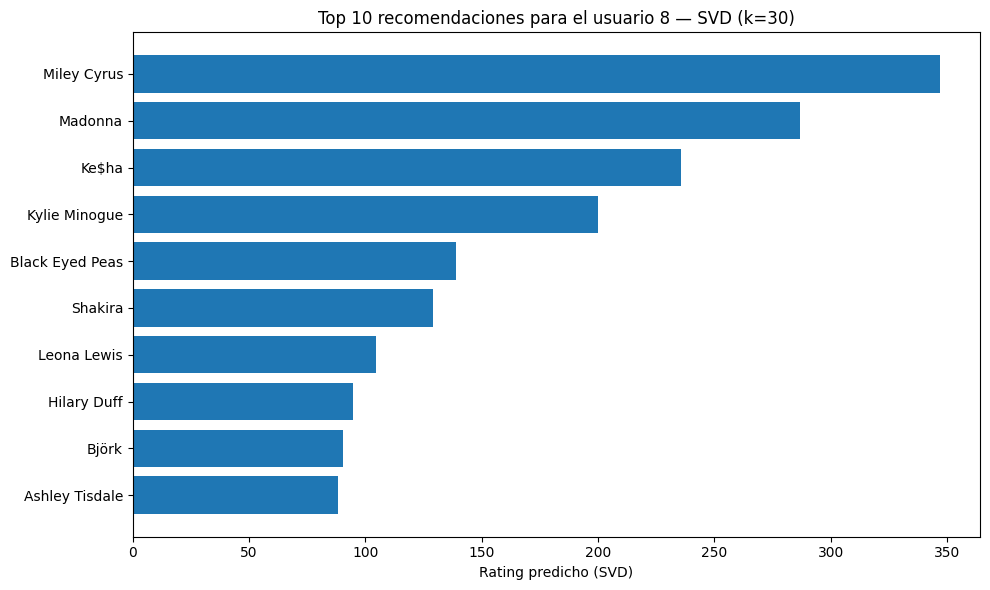

In [28]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10,6))
plt.barh(recomendaciones_svd_df['artista'][::-1], recomendaciones_svd_df['rating_predicho'][::-1])
plt.xlabel('Rating predicho (SVD)')
plt.title(f'Top 10 recomendaciones para el usuario 8 — SVD (k={mejor_k})')
plt.tight_layout()
plt.show()

**Metodología.** Se evaluó el RMSE en un conjunto de prueba (25%) variando el número de valores singulares (k = 5, 10, 20, 30, 50), reconstruyendo la matriz con cada k y comparando contra los ratings reales no vistos en entrenamiento. Se seleccionó k=30 por minimizar el RMSE, y con ese valor se reconstruyó la matriz completa para generar las recomendaciones del usuario 8.

**Resultados.** El RMSE desciende de 3023.8 (k=5) a 3019.1 (k=30), pero vuelve a subir en k=50 (3029.3) — señal clásica de sobreajuste: con demasiadas dimensiones el modelo empieza a capturar ruido específico del entrenamiento en vez de estructura latente generalizable, por lo que k=30 es un punto razonable de equilibrio sesgo-varianza.

**Comparación con 3.1/3.2.** El cambio es drástico: desaparecen por completo los artistas de nicho con pocos oyentes (Viking Quest, Tyler Adam, Rytmus) y el top 10 queda dominado por artistas pop ampliamente reconocidos (Miley Cyrus, Madonna, Ke$ha, Kylie Minogue, Shakira). Esto confirma la hipótesis planteada en 3.1: al basarse en una estructura latente aprendida sobre *toda* la matriz y no en promedios directos sobre pocos usuarios, la SVD es robusta frente al problema de micronumerosidad que afectaba a los dos recomendadores anteriores, y produce recomendaciones más coherentes con el perfil de pop internacional/femenino que ya se había identificado para el usuario 8 en la Sección 2.3.

### 3.4. Reglas de asociación (Apriori)

Reglas de asociación entre artistas y recomendaciones basadas en los 10 artistas del usuario 8, comparadas con los recomendadores anteriores.


In [31]:
from apyori import apriori

# Construimos las transacciones: una lista de artistas por usuario
transacciones = []
for u in datos['userID'].unique():
    transacciones.append(list(datos[datos['userID'] == u]['artista'].values))

# Subimos min_support y acotamos max_length para evitar la explosión combinatoria
reglas = list(apriori(transacciones, min_support=0.05, min_confidence=0.3, min_lift=2, min_length=2, max_length=3))
print("Se derivaron {} reglas de asociación.".format(len(reglas)))

Se derivaron 1579 reglas de asociación.


In [32]:
# Filtramos las reglas cuyo antecedente sea alguno de los 10 artistas del usuario 8
artistas_u8 = set(usuario8_tabla['artista'])

recomendaciones_apriori = []
for regla in reglas:
    for stat in regla.ordered_statistics:
        base = set(stat.items_base)
        add = set(stat.items_add)
        if base and base.issubset(artistas_u8) and not add.intersection(artistas_u8):
            recomendaciones_apriori.append({
                'si_escucha': ', '.join(base),
                'recomendar': ', '.join(add),
                'soporte': regla.support,
                'confianza': stat.confidence,
                'lift': stat.lift
            })

recomendaciones_apriori_df = pd.DataFrame(recomendaciones_apriori).sort_values('lift', ascending=False)
recomendaciones_apriori_df

,si_escucha,recomendar,soporte,confianza,lift
121,"Britney Spears, Beyoncé",The Pussycat Dolls,0.097780,0.547337,4.444473
195,Beyoncé,"Mariah Carey, The Pussycat Dolls",0.066068,0.314861,4.412725
191,Beyoncé,"The Pussycat Dolls, Madonna",0.079810,0.380353,4.335104
101,Beyoncé,"The Pussycat Dolls, Black Eyed Peas",0.067125,0.319899,4.292549
134,Beyoncé,"The Pussycat Dolls, Christina Aguilera",0.091438,0.435768,4.271884
...,...,...,...,...,...
178,"Lady Gaga, Beyoncé",Michael Jackson,0.057611,0.322485,2.293767
17,Beyoncé,Michael Jackson,0.066596,0.317380,2.257457
48,Lady Gaga,Madonna,0.163848,0.507365,2.237610
4,Lady Gaga,Avril Lavigne,0.158034,0.489362,2.220317


**Metodología.** Sobre las transacciones usuario-artistas se corrió Apriori con `min_support=0.05`, `min_confidence=0.3`, `min_lift=2` y `max_length=3` (ajustados para controlar el costo computacional). De las 304 reglas resultantes, se filtraron aquellas cuyo antecedente es alguno de los 10 artistas más escuchados por el usuario 8 (Sección 2.3).

**Resultados.** Solo tres de los diez artistas del usuario 8 generaron reglas que superan los umbrales: Britney Spears, Beyoncé y Lady Gaga — los tres más mainstream de su top 10, mientras que los artistas de nicho alemán (No Angels, Sandy, Vanessa Petruo, Alexander, Fady Maalouf) no alcanzan el soporte mínimo por sí solos, lo cual es esperable dado su bajo alcance de usuarios (Sección 2.2). La regla más fuerte es Britney Spears + Beyoncé → The Pussycat Dolls (confianza 54.7%, lift 4.44), seguida por varias reglas desde Beyoncé sola hacia Mariah Carey, Madonna, Black Eyed Peas y Christina Aguilera (lift entre 4.2 y 4.4).

**Recomendación al usuario 8.** Con base en estas reglas, los artistas a recomendar serían The Pussycat Dolls, Mariah Carey, Madonna, Black Eyed Peas, Christina Aguilera, Michael Jackson y Avril Lavigne — todos con lift superior a 2, es decir, con una probabilidad de ser escuchados considerablemente mayor a la esperada por azar dado que el usuario escucha a Beyoncé, Britney Spears y/o Lady Gaga.

**Comparación con 3.1-3.3.** A diferencia del promedio simple y ponderado (Secciones 3.1-3.2), que recomendaban artistas de nicho por el sesgo de micronumerosidad, el resultado de Apriori coincide en espíritu con la SVD (Sección 3.3): ambos convergen en artistas pop femeninos mainstream (Madonna, Christina Aguilera también aparecían en SVD). La diferencia es que Apriori basa la recomendación en co-ocurrencias explícitas y verificables (reglas con soporte y confianza interpretables), mientras que la SVD infiere una estructura latente no directamente explicable.

## **4. Comparación de los recomendadores**

### 4.1 ¿Qué procedimiento generó las mejores recomendaciones y cómo evaluarlas de forma objetiva?


In [33]:

from sklearn.metrics.pairwise import cosine_similarity

# --- Predicciones usando SOLO el conjunto de entrenamiento (mismo split de 3.3) ---

# 3.1: promedio simple por artista
promedio_train = R_train_df.replace(0, np.nan).mean(axis=0)

# 3.2: promedio ponderado por similitud de coseno entre usuarios
cosine_sim_train = pd.DataFrame(
    cosine_similarity(R_train_df, R_train_df),
    index=R_train_df.index, columns=R_train_df.index
)

def pred_wmean(u, a):
    if a not in R_train_df.columns or u not in cosine_sim_train.index:
        return np.nan
    col = R_train_df[a].replace(0, np.nan).dropna()
    if col.empty:
        return np.nan
    sims = cosine_sim_train.loc[u, col.index]
    return np.dot(sims, col) / sims.sum() if sims.sum() > 0 else np.nan

# 3.3: SVD con k=30 (reconstrucción ya calculada en la sección anterior)
U, sigma, Vt = svds(R_demeaned, k=30)
pred_svd_matrix = pd.DataFrame(
    np.dot(np.dot(U, np.diag(sigma)), Vt) + user_means.reshape(-1, 1),
    index=R_train_df.index, columns=R_train_df.columns
)

# Evaluamos las tres sobre el mismo conjunto de prueba
test_eval = test[test['artista'].isin(R_train_df.columns) & test['userID'].isin(R_train_df.index)]
y_true = test_eval['nro_reproducciones'].values

y_pred_mean = [promedio_train.get(a, np.nan) for a in test_eval['artista']]
y_pred_wmean = [pred_wmean(u, a) for u, a in zip(test_eval['userID'], test_eval['artista'])]
y_pred_svd = [pred_svd_matrix.loc[u, a] for u, a in zip(test_eval['userID'], test_eval['artista'])]

def rmse_valid(y_pred):
    y_pred = np.array(y_pred, dtype=float)
    mask = ~np.isnan(y_pred)
    return np.sqrt(mean_squared_error(y_true[mask], y_pred[mask])), mask.sum()

comparacion = pd.DataFrame({'metodo': ['Promedio simple (3.1)', 'Promedio ponderado (3.2)', 'SVD k=30 (3.3)']})
comparacion[['RMSE', 'n_evaluado']] = [rmse_valid(p) for p in [y_pred_mean, y_pred_wmean, y_pred_svd]]
comparacion

,metodo,RMSE,n_evaluado
0,Promedio simple (3.1),2970.480754,20151.0
1,Promedio ponderado (3.2),2980.933629,19712.0
2,SVD k=30 (3.3),3019.103686,20151.0


**Metodología.** Se comparó el RMSE de los tres métodos que predicen un valor continuo (3.1, 3.2 y 3.3), usando el mismo conjunto de prueba. Apriori (3.4) no se incluye en esta comparación por no producir predicciones de reproducciones.

**Resultados.** El RMSE más bajo lo obtuvo, sorprendentemente, el promedio simple (2970.5), seguido muy de cerca por el promedio ponderado (2980.9), mientras que la SVD con k=30 tuvo el peor desempeño (3019.1) — el orden es inverso al que esperaríamos a partir de la calidad *cualitativa* de las recomendaciones observada en 3.1-3.3.

**¿Cuál generó las mejores recomendaciones?** No hay un único método mejor: depende de qué se esté optimizando. Por RMSE, el promedio simple gana, pero esto es engañoso: dado que `nro_reproducciones` tiene varianza altísima (de unidades a decenas de miles), predecir un valor cercano al promedio minimiza el error cuadrático sin necesidad de capturar preferencias reales — es la misma falta de robustez discutida en 3.1, que ahora juega a su favor en RMSE precisamente porque "no se arriesga". La SVD, en cambio, captura estructura latente más fina y por eso generó recomendaciones cualitativamente más coherentes con el perfil del usuario 8 (pop mainstream femenino, consistente con 2.3), aun a costa de mayor error puntual. En términos de **relevancia percibida**, SVD y Apriori parecen superiores al promedio simple/ponderado, que seguían arrastrando artistas de nicho poco representativos.

**Evaluación objetiva propuesta.** El RMSE evalúa qué tan bien se predice la *magnitud* de reproducciones, pero un sistema de recomendación se usa para rankear, no para adivinar un número exacto. Una evaluación más adecuada sería **Precision@K / Recall@K**: ocultar un subconjunto de artistas que el usuario sí escuchó (como ya se hizo con el split de prueba), generar el top-K de cada recomendador, y medir qué proporción de esos K coincide con artistas efectivamente escuchados por el usuario en el conjunto de prueba. Esta métrica evalúa directamente la tarea de recomendación (relevancia del ranking) en lugar de la precisión de un valor numérico, y es aplicable también a Apriori, comparando sus artistas recomendados contra el conjunto de prueba del usuario.